# Smart Crop Recommendation using Artificial Neural Network (ANN)

This notebook develops a **multi-class Artificial Neural Network (ANN)** using TensorFlow/Keras to classify a crop label from soil nutrient and climate-related input features.

### Project Overview
- **Dataset:** `crop_recommendation.csv` (1,750 records and 7 input features)
- **Dataset origin:** The complete dataset was generated with assistance from **Google Gemini**. It is a synthetic, AI-generated dataset created for educational and machine-learning experimentation; it is not a collection of real agricultural field measurements.
- **Input features:** Soil Nitrogen (`nitrogen`), Phosphorus (`phosphorus`), Potassium (`potassium`), `temperature` (°C), `humidity` (%), soil `ph`, and `rainfall` (mm)
- **Target (`crop_label`):** 7 crop classes — `chickpea`, `coffee`, `cotton`, `maize`, `mango`, `pomegranate`, and `rice`
- **Task:** Multi-class classification
- **ANN output layer:** 7 neurons with `softmax` activation to produce a probability for each crop class
- **Loss function:** `sparse_categorical_crossentropy`, used with integer-encoded class labels

> **Dataset limitation:** Since the dataset is synthetic and AI-generated, the model's results describe performance on this dataset only. They should not be interpreted as evidence of accuracy on real farms or as validated agronomic advice.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Set visual theme and random seeds for reproducible results
sns.set_theme(style="whitegrid")
np.random.seed(42)
tf.random.set_seed(42)

## 1. Load and inspect the dataset

We load `crop_recommendation.csv` and check its dimensions, column types, and sample records.

In [ ]:
df = pd.read_csv("crop_recommendation.csv")

print("Dataset Shape:", df.shape)
display(df.head())
print("\nDataset Info:")
print(df.info())

Dataset Shape: (1750, 8)


,nitrogen,phosphorus,potassium,temperature,humidity,ph,rainfall,crop_label
0,97.9,43.3,26.3,28.28,79.51,7.39,106.53,cotton
1,125.0,24.5,23.8,25.79,58.58,6.67,200.21,coffee
2,70.7,49.0,19.5,17.94,69.73,6.64,80.06,maize
3,111.3,19.9,28.4,25.85,58.96,6.03,160.30,coffee
4,21.1,28.2,34.5,21.78,84.93,6.17,83.00,pomegranate



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1750 entries, 0 to 1749
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   nitrogen     1750 non-null   float64
 1   phosphorus   1750 non-null   float64
 2   potassium    1750 non-null   float64
 3   temperature  1750 non-null   float64
 4   humidity     1750 non-null   float64
 5   ph           1750 non-null   float64
 6   rainfall     1750 non-null   float64
 7   crop_label   1750 non-null   object 
dtypes: float64(7), object(1)
memory usage: 109.5+ KB
None


## 2. Data quality check & Exploratory Data Analysis (EDA)

Before training the neural network, we inspect:
1. Missing values and duplicate rows.
2. The number of records in each of the 7 crop classes (`01_crop_class_distribution.png`).
3. Patterns in soil nutrients and climate-related features across crop labels, using the following visualizations:
   - Average soil NPK levels by crop (`02_avg_npk_by_crop.png`)
   - Rainfall versus humidity (`03_rainfall_vs_humidity.png`)
   - Soil pH density distribution (`04_ph_kde_density.png`)
   - Feature correlation heatmap (`05_correlation_heatmap.png`)

These plots describe patterns in the synthetic dataset; they should not be assumed to represent real-world agricultural relationships.


In [ ]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget class distribution:")
print(df["crop_label"].value_counts())

display(df.describe().T[["min", "mean", "std", "max"]])

Missing values: 0
Duplicate rows: 0

Target class distribution:
crop_label
cotton         250
coffee         250
maize          250
pomegranate    250
chickpea       250
mango          250
rice           250
Name: count, dtype: int64


,min,mean,std,max
nitrogen,0.00,65.244514,37.051948,150.00
phosphorus,5.00,41.032629,17.064364,95.40
potassium,6.70,37.337086,19.463491,103.20
temperature,13.61,24.049531,4.126456,38.05
humidity,14.00,63.718920,22.540314,100.00
ph,4.39,6.523114,0.676836,8.91
rainfall,27.53,118.995851,52.523172,300.00


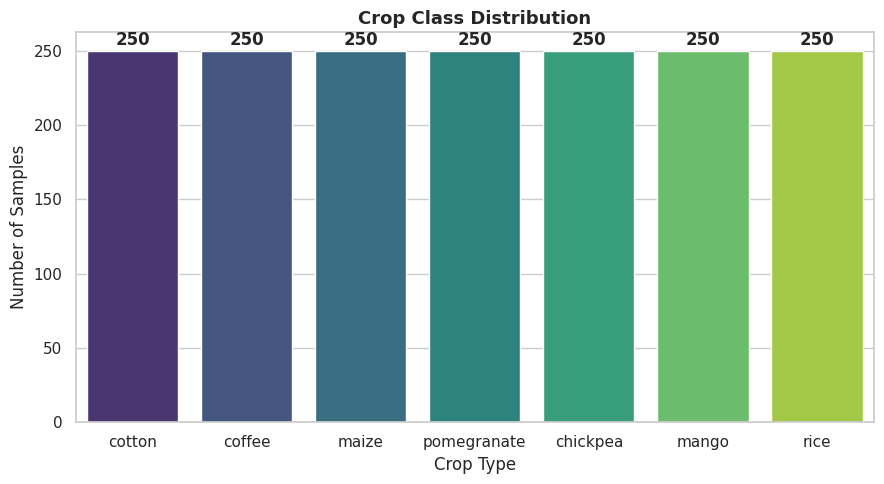

In [ ]:
# Picture 1: Crop Class Distribution
plt.figure(figsize=(9, 5))
class_counts = df["crop_label"].value_counts()
ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette="viridis",
    legend=False
)
plt.title("Crop Class Distribution", fontsize=13, fontweight="bold")
plt.xlabel("Crop Type")
plt.ylabel("Number of Samples")
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 4, str(v), ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("01_crop_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

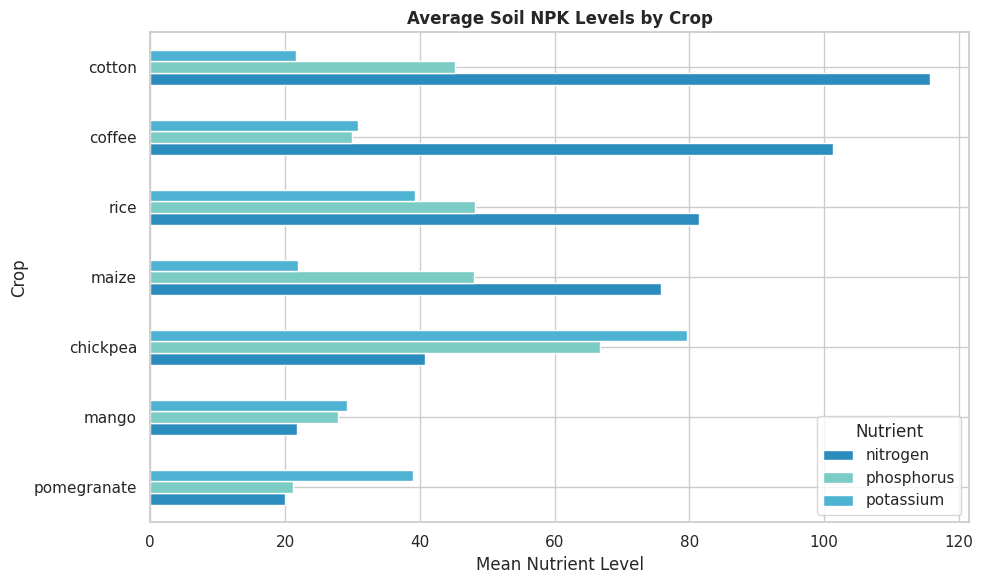

In [ ]:
npk_means = df.groupby("crop_label")[["nitrogen", "phosphorus", "potassium"]].mean().sort_values("nitrogen")
ax = npk_means.plot(kind="barh", figsize=(10, 6), color=["#2b8cbe", "#7bccc4", "#4eb3d3"])
plt.title("Average Soil NPK Levels by Crop", fontweight="bold")
plt.xlabel("Mean Nutrient Level")
plt.ylabel("Crop")
plt.legend(title="Nutrient")
plt.tight_layout()
plt.savefig("02_avg_npk_by_crop.png", dpi=300, bbox_inches="tight")
plt.show()

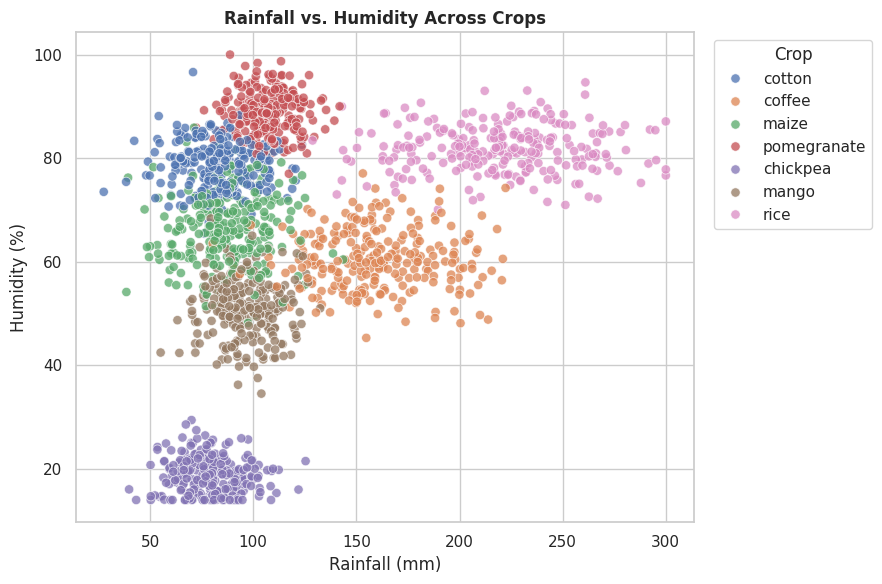

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="rainfall", y="humidity", hue="crop_label", alpha=0.75, s=45)
plt.title("Rainfall vs. Humidity Across Crops", fontweight="bold")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Humidity (%)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Crop")
plt.tight_layout()
plt.savefig("03_rainfall_vs_humidity.png", dpi=300, bbox_inches="tight")
plt.show()

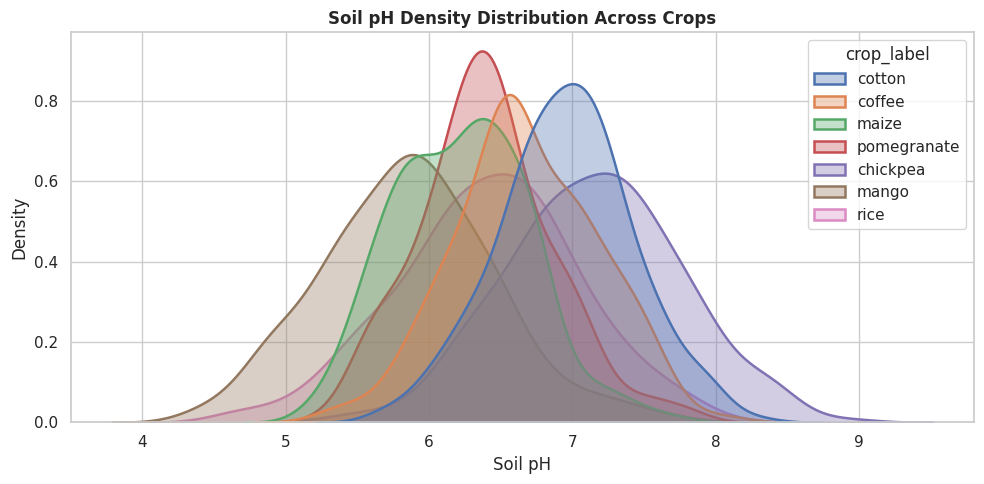

In [ ]:
# 4. Soil pH Density Distribution Across Crops (KDE Plot)
plt.figure(figsize=(10, 5))
sns.kdeplot(
    data=df, x="ph", hue="crop_label",
    fill=True, common_norm=False, alpha=0.35, linewidth=1.8
)
plt.title("Soil pH Density Distribution Across Crops", fontweight="bold")
plt.xlabel("Soil pH")
plt.ylabel("Density")
plt.tight_layout()
plt.savefig("04_ph_kde_density.png", dpi=300, bbox_inches="tight")
plt.show()

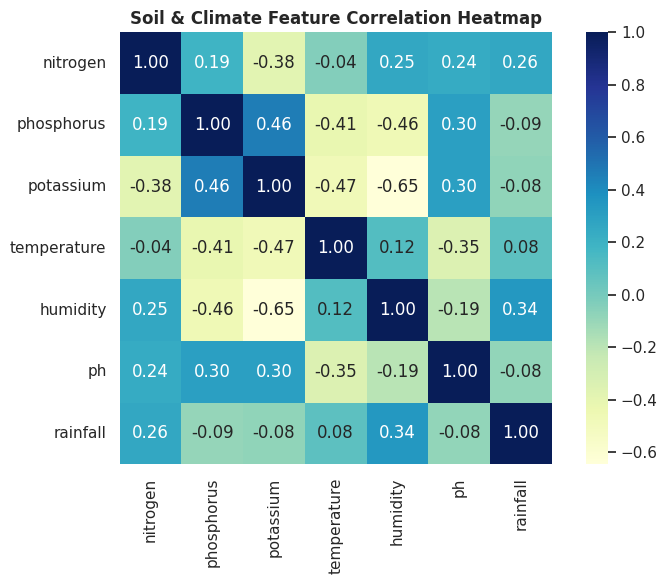

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.drop(columns=["crop_label"]).corr(), annot=True, fmt=".2f", cmap="YlGnBu", square=True)
plt.title("Soil & Climate Feature Correlation Heatmap", fontweight="bold")
plt.tight_layout()
plt.savefig("05_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Separate features, clean duplicates, and encode the target

All 7 input features are continuous numerical values (`float64`), so no one-hot encoding is needed for `X`.

We use `LabelEncoder` to map the 7 text crop names into integer IDs (`0` through `6`), matching Keras's `sparse_categorical_crossentropy` loss function.

In [ ]:
df = df.drop_duplicates().copy()

X = df.drop(columns=["crop_label"])
y_text = df["crop_label"].str.strip()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

class_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Class Mapping:", class_mapping)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Class Mapping: {'chickpea': np.int64(0), 'coffee': np.int64(1), 'cotton': np.int64(2), 'maize': np.int64(3), 'mango': np.int64(4), 'pomegranate': np.int64(5), 'rice': np.int64(6)}
Features shape: (1750, 7)
Target shape: (1750,)


## 4. Train-test split and feature scaling

We apply an **80/20 stratified split** (`stratify=y`) so every crop class maintains equal representation in both training and testing splits.

Because `rainfall` (up to ~300 mm) and `ph` (~3.5–9.9) operate on completely different scales, `StandardScaler` standardizes each feature to mean `0` and standard deviation `1`. Fitting on `X_train` only prevents data leakage.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (1400, 7)
Testing set shape: (350, 7)


## 5. Build the Artificial Neural Network (ANN)

Our multi-class neural network architecture uses:
- **Input layer:** 7 standardized soil and climate features.
- **Hidden layers:** Two `Dense` layers (`64` and `32` neurons) with `ReLU` activation to capture non-linear relationships between soil NPK ratios and weather.
- **Dropout layers (20%):** Regularizes the network during training to prevent overfitting.
- **Output layer:** 7 neurons with `softmax` activation, outputting predicted probabilities for each crop.

In [ ]:
num_classes = len(label_encoder.classes_)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,823 (11.03 KB)

 Trainable params: 2,823 (11.03 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile and train the model

We train using `Adam` (`learning_rate=0.001`), `sparse_categorical_crossentropy`, and `EarlyStopping` (`patience=10`) to restore the best validation weights automatically.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=80,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/80
35/35 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.4634 - loss: 1.5821 - val_accuracy: 0.7429 - val_loss: 1.2281
Epoch 2/80
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7259 - loss: 1.1084 - val_accuracy: 0.8571 - val_loss: 0.7679
Epoch 3/80
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8366 - loss: 0.7276 - val_accuracy: 0.9321 - val_loss: 0.4310
Epoch 4/80
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8991 - loss: 0.4718 - val_accuracy: 0.9750 - val_loss: 0.2461
Epoch 5/80
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9339 - loss: 0.3136 - val_accuracy: 0.9786 - val_loss: 0.1637
Epoch 6/80
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9491 - loss: 0.2233 - val_accuracy: 0.9821 - val_loss: 0.1227
Epoch 7/80
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9563 - loss: 0.1819 - val_accuracy: 0.9786 - val_loss: 0.1005
Epoch 8/80
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9625 - loss: 0.1542 - val_accuracy: 0.9821 - val_loss

## 7. Plot training vs. validation performance

We visualize accuracy and loss across training epochs (`04_training_validation_curves.png`) to inspect how the model learns and whether the training and validation curves show signs of divergence. These curves reflect performance on the synthetic dataset and do not establish real-world predictive performance.


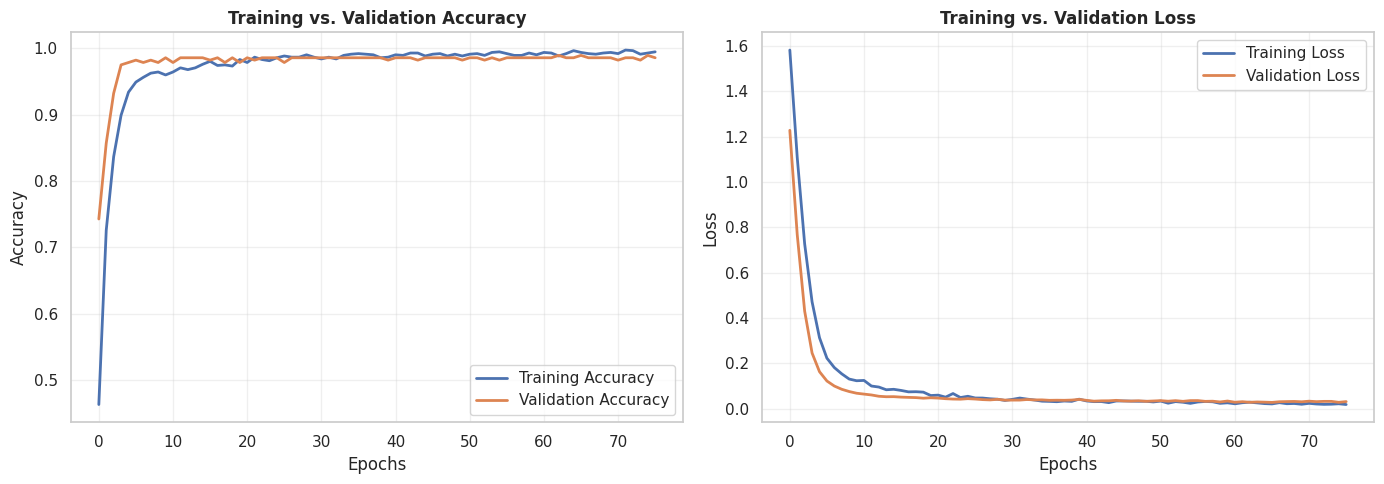

In [ ]:
# Picture 4: Training vs. Validation Accuracy & Loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curve
axes[0].plot(history.history["accuracy"], label="Training Accuracy", linewidth=2)
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy", linewidth=2)
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Training vs. Validation Accuracy", fontweight="bold")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss curve
axes[1].plot(history.history["loss"], label="Training Loss", linewidth=2)
axes[1].plot(history.history["val_loss"], label="Validation Loss", linewidth=2)
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].set_title("Training vs. Validation Loss", fontweight="bold")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("04_training_validation_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Evaluate the model on the test set

We evaluate the trained ANN using the held-out test split and review its accuracy, classification report, and confusion matrix (`05_confusion_matrix.png`). The saved notebook result reports **98.86% test accuracy** on this synthetic dataset.

This score measures classification performance on the selected test split only. Because the records were generated using Google Gemini rather than collected from real agricultural fields, the result should not be interpreted as validated performance on real-world farm data.


Test Accuracy: 98.29%

Classification Report:
              precision    recall  f1-score   support

    chickpea       1.00      1.00      1.00        50
      coffee       0.98      1.00      0.99        50
      cotton       0.96      0.96      0.96        50
       maize       0.96      0.94      0.95        50
       mango       0.98      1.00      0.99        50
 pomegranate       1.00      1.00      1.00        50
        rice       1.00      0.98      0.99        50

    accuracy                           0.98       350
   macro avg       0.98      0.98      0.98       350
weighted avg       0.98      0.98      0.98       350



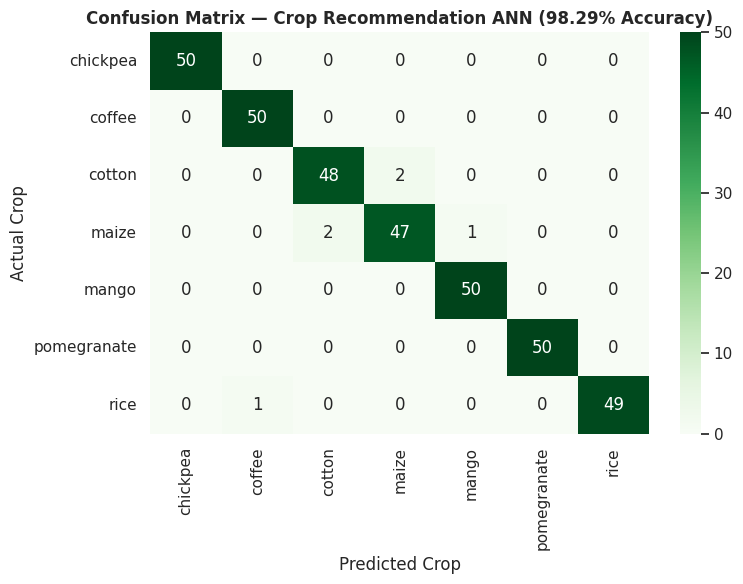

,Actual,Predicted,Confidence
0,mango,mango,1.000
1,pomegranate,pomegranate,1.000
2,chickpea,chickpea,1.000
3,coffee,coffee,1.000
4,mango,mango,1.000
5,coffee,coffee,1.000
6,pomegranate,pomegranate,1.000
7,cotton,cotton,0.997
8,mango,mango,1.000
9,cotton,cotton,0.979


In [ ]:
probabilities = model.predict(X_test, verbose=0)
predictions = np.argmax(probabilities, axis=1)

test_accuracy = accuracy_score(y_test, predictions)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, predictions, target_names=label_encoder.classes_))

# Picture 5: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.title(f"Confusion Matrix — Crop Recommendation ANN ({test_accuracy * 100:.2f}% Accuracy)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("06_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Preview actual vs predicted labels with confidence score
results = pd.DataFrame({
    "Actual": label_encoder.inverse_transform(y_test),
    "Predicted": label_encoder.inverse_transform(predictions),
    "Confidence": np.round(np.max(probabilities, axis=1), 3)
})
display(results.head(10))

## 9. Predict a crop class for new soil & weather readings

Enter soil NPK values, temperature, humidity, pH, and rainfall below to obtain the model's predicted crop class and its probability scores.

The example prediction is an output of a model trained on synthetic, AI-generated data. It is for demonstrating the classification workflow and should not be used as an actual farming recommendation.


In [ ]:
new_sample = pd.DataFrame([{
    "nitrogen": 98.0,
    "phosphorus": 28.0,
    "potassium": 31.0,
    "temperature": 25.2,
    "humidity": 61.0,
    "ph": 6.6,
    "rainfall": 165.0
}])

new_sample_scaled = scaler.transform(new_sample)
pred_probs = model.predict(new_sample_scaled, verbose=0)[0]
pred_class_idx = np.argmax(pred_probs)
pred_crop = label_encoder.inverse_transform([pred_class_idx])[0]

print(f"Recommended Crop: {pred_crop.upper()} (Confidence: {pred_probs[pred_class_idx] * 100:.2f}%)")
print("\nClass Probabilities:")
for crop_name, prob in zip(label_encoder.classes_, pred_probs):
    print(f"  {crop_name:>11}: {prob * 100:.2f}%")

Recommended Crop: COFFEE (Confidence: 99.99%)

Class Probabilities:
     chickpea: 0.00%
       coffee: 99.99%
       cotton: 0.00%
        maize: 0.00%
        mango: 0.00%
  pomegranate: 0.00%
         rice: 0.01%


## 10. Key Takeaways

- **Multi-class classification:** The ANN uses `LabelEncoder`, `StandardScaler`, and a 7-neuron `softmax` output layer with `sparse_categorical_crossentropy` to classify the seven crop labels.
- **Model evaluation:** The saved evaluation output reports approximately **98.86% test accuracy** on the held-out portion of this synthetic dataset.
- **Training controls:** `Dropout(0.2)` and `EarlyStopping` are used during training. The training and validation curves help inspect the model's learning behavior.
- **Dataset limitation:** The full dataset was generated using Google Gemini for this project. It is synthetic and does not represent measured agricultural field data, so the reported performance cannot establish how the model would perform under real farming conditions.


## 11. Conclusion

This notebook demonstrates a multi-class classification workflow using an Artificial Neural Network to predict one of seven crop labels from soil nutrient and climate-related input features. The workflow includes exploratory data analysis, duplicate handling, target encoding, an 80/20 stratified train-test split, feature scaling, ANN training, and test-set evaluation.

The saved evaluation result is **98.86% test accuracy** on this project's synthetic dataset. The dataset was generated in full with assistance from Google Gemini for educational and machine-learning experimentation purposes; it does not contain real agricultural field measurements. Therefore, the result should be understood as performance on this synthetic dataset, not as proof of real-world agricultural accuracy or a validated crop recommendation system.
